# 01 — Análise exploratória (EDA)

Fase 2 do plano. Objetivos:

1. Entender estrutura, tipos, nulos, período coberto e granularidade dos dois CSVs do Zenodo.
2. Caracterizar as distribuições de CPU e memória.
3. Verificar se existe rótulo ou proxy de falha que sustente a
   avaliação com "períodos de falha documentada" prometida no artigo?

**Fontes**

- Fernández-Montes e Fernández Cerero (2024), *DataCenter-Traces-Datasets*, Zenodo, registro 14564935 (CC-BY 4.0).
  Arquivos `machine_usage_days_1_to_8_grouped_300_seconds.csv` (Alibaba 2018) e
  `instance_usage_grouped_300_seconds_month.csv` (Google 2019). Checksums MD5 conferidos com o registro.
- Trace original da Alibaba, `cluster-trace-v2018`: arquivos `machine_meta`, `batch_task` e `machine_usage`,
  baixados com o `fetchData.sh` do repositório oficial para `data/raw/alibaba_v2018/`.
  O `machine_usage` foi agregado em janelas de 300 s **com timestamp** por `src/build_alibaba_aggregate.py`.
- Documentação oficial do Google *cluster-usage traces v3* (Wilkes, 2020), para a seção 6.5.

Figuras salvas em `results/figures/`, tabelas em `results/tables/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import (ALIBABA_GAP_AFTER_ROW, ALIBABA_GAP_WINDOWS, ALIBABA_ORIGINAL_300S, RAW,
                      STEP_SECONDS, load_alibaba, load_google)

FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
ALI_ORIG = RAW / "alibaba_v2018"

# Cor segue o dataset em todas as figuras (paleta validada para daltonismo).
COR = {"Alibaba 2018": "#2a78d6", "Google 2019": "#eb6834"}
CINZA = "#52514e"
DESTAQUE = "#d9d8d3"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "lines.linewidth": 0.9,
    "xtick.color": CINZA,
    "ytick.color": CINZA,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)


def br(x, casas=None):
    # Vírgula decimal (padrão do texto em português).
    txt = f"{x:g}" if casas is None else f"{x:.{casas}f}"
    return txt.replace(".", ",")


def eixos_br(fig):
    fmt = FuncFormatter(lambda x, _: br(round(x, 6)))
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(fmt)
        ax.yaxis.set_major_formatter(fmt)


def em_dias(index):
    return index / pd.Timedelta(days=1)

## 1. Carga e estrutura

In [2]:
ali = load_alibaba()
goo = load_google()
DATASETS = {"Alibaba 2018": ali, "Google 2019": goo}

for nome, df in DATASETS.items():
    print(f"{nome}: {df.shape[0]} linhas x {df.shape[1]} colunas")
    print(df.dtypes.to_string(), end="\n\n")

Alibaba 2018: 2243 linhas x 5 colunas
cpu_util_percent    float64
mem_util_percent    float64
net_in              float64
net_out             float64
disk_io_percent     float64

Google 2019: 8064 linhas x 4 colunas
avg_cpu                       float64
avg_mem                       float64
avg_assigned_mem              float64
avg_cycles_per_instruction    float64



In [3]:
ali.head()

,cpu_util_percent,mem_util_percent,net_in,net_out,disk_io_percent
t,,,,,
0 days 00:00:00,16.1270,87.1390,34.8891,27.6575,4.0867
0 days 00:05:00,18.4661,86.8581,34.9129,27.6729,4.1930
0 days 00:10:00,30.8225,89.9884,34.9301,27.6583,5.9925
0 days 00:15:00,24.6563,86.8237,34.9501,27.6681,4.2260
0 days 00:20:00,30.1752,89.1262,34.9950,27.7272,5.0466


In [4]:
goo.head()

,avg_cpu,avg_mem,avg_assigned_mem,avg_cycles_per_instruction
t,,,,
0 days 00:00:00,0.4416,0.3324,0.6240,148.6176
0 days 00:05:00,0.4331,0.3267,0.6157,148.2062
0 days 00:10:00,0.4114,0.3234,0.6074,146.5902
0 days 00:15:00,0.4080,0.3271,0.6095,147.0947
0 days 00:20:00,0.4168,0.3337,0.6135,149.0821


**O que a estrutura mostra (e o que falta):**

- **Não há coluna de tempo.** Cada linha é uma janela de 300 s em sequência. O índice `t` foi reconstruído em
  `src/data.py`. No Alibaba, a reconstrução considera uma lacuna encontrada na seção 3.2.
- **Não há identificador de máquina ou instância.** Segundo a descrição do registro Zenodo, cada valor é a
  *média de todo o datacenter* naquela janela. Cada arquivo é, portanto, **uma única série temporal
  multivariada**, e não milhares de séries de máquinas.
- **Não há coluna de rótulo, status ou evento.** Nada nos arquivos indica falha.
- O Google traz uma quarta coluna, `avg_cycles_per_instruction`, que não está entre as features prometidas no artigo.

## 2. Nulos, duplicados e faixas válidas

Faixas segundo a documentação do Zenodo: Alibaba em [0, 100] (no original, `disk_io_percent` usa -1 e 101
como valores inválidos); Google em [0, 1], exceto CPI (≥ 0).

In [5]:
FAIXAS = {
    "Alibaba 2018": {c: (0, 100) for c in ali.columns},
    "Google 2019": {"avg_cpu": (0, 1), "avg_mem": (0, 1), "avg_assigned_mem": (0, 1),
                    "avg_cycles_per_instruction": (0, np.inf)},
}

linhas = []
for nome, df in DATASETS.items():
    for col, (lo, hi) in FAIXAS[nome].items():
        s = df[col]
        linhas.append({
            "dataset": nome, "coluna": col, "nulos": int(s.isna().sum()),
            "min": s.min(), "max": s.max(), "faixa_documentada": f"[{lo}, {hi}]",
            "fora_da_faixa": int(((s < lo) | (s > hi)).sum()),
        })
    print(f"{nome}: linhas duplicadas = {df.duplicated().sum()}")

qualidade = pd.DataFrame(linhas)
qualidade

Alibaba 2018: linhas duplicadas = 0
Google 2019: linhas duplicadas = 0


,dataset,coluna,nulos,min,max,faixa_documentada,fora_da_faixa
0,Alibaba 2018,cpu_util_percent,0,16.1270,79.0743,"[0, 100]",0
1,Alibaba 2018,mem_util_percent,0,78.2643,95.0207,"[0, 100]",0
2,Alibaba 2018,net_in,0,34.7008,47.4591,"[0, 100]",0
3,Alibaba 2018,net_out,0,27.4934,37.7708,"[0, 100]",0
4,Alibaba 2018,disk_io_percent,0,3.3143,25.7999,"[0, 100]",0
5,Google 2019,avg_cpu,0,0.3203,0.5924,"[0, 1]",0
6,Google 2019,avg_mem,0,0.2450,0.4022,"[0, 1]",0
7,Google 2019,avg_assigned_mem,0,0.4954,0.7190,"[0, 1]",0
8,Google 2019,avg_cycles_per_instruction,0,119.7191,201.3132,"[0, inf]",0


Nenhum nulo, nenhuma linha duplicada e nenhum valor fora da faixa documentada. Os percentuais do Alibaba,
que no original são inteiros (`bigint`), aqui são `float` justamente por serem médias. A limpeza "clássica"
(nulos, duplicados, faixa) não tem o que fazer; os problemas de qualidade reais aparecem nas seções 3 e 4.

## 3. Período coberto e granularidade

### 3.1 O que os CSVs dizem sozinhos

In [6]:
JANELAS_POR_DIA = 86400 // STEP_SECONDS  # 288

for nome, df in DATASETS.items():
    print(f"{nome}: {len(df)} linhas (janelas de {STEP_SECONDS} s) = {len(df) / JANELAS_POR_DIA:.2f} dias de dados")

print(f"\nAlibaba: o trace original declara 8 dias = {8 * JANELAS_POR_DIA} janelas; "
      f"o CSV tem {8 * JANELAS_POR_DIA - len(ali)} a menos.")

Alibaba 2018: 2243 linhas (janelas de 300 s) = 7.79 dias de dados
Google 2019: 8064 linhas (janelas de 300 s) = 28.00 dias de dados

Alibaba: o trace original declara 8 dias = 2304 janelas; o CSV tem 61 a menos.


- **Alibaba 2018:** 2243 linhas ≈ 7,79 dias, contra 8 dias (2304 janelas) declarados no trace original. Só com
  o CSV não dá para saber onde estão as janelas ausentes. A seção 3.2 resolve isso.
- **Google 2019:** 8064 linhas = exatamente 28 dias. O trace original cobre o mês de maio de 2019 (31 dias) em
  **oito células** (a–h). O registro Zenodo **não informa qual célula nem quais dias** foram usados, e não há
  como verificar lacunas sem consultar o BigQuery. Limitação a registrar no TCC.

### 3.2 Verificação com o trace original da Alibaba

O `machine_usage` original (≈ 9 GB descompactado, 4034 máquinas, amostras a cada 10 s) foi agregado pela média
de todas as máquinas em janelas de 300 s, mantendo o início de cada janela em segundos
(`src/build_alibaba_aggregate.py`).

In [7]:
orig = pd.read_csv(ALIBABA_ORIGINAL_300S)
orig["janela"] = orig["t_inicio_s"] // STEP_SECONDS

saltos = np.diff(orig["janela"].to_numpy())
pos = np.flatnonzero(saltos > 1)
print(f"Janelas no trace original agregado: {len(orig)} (CSV do Zenodo: {len(ali)})")
for i in pos:
    ini, fim = orig["janela"].iloc[i], orig["janela"].iloc[i + 1]
    print(f"Lacuna: depois da linha {i} (janela {ini}, dia {ini / JANELAS_POR_DIA:.2f}) até a janela {fim}: "
          f"{fim - ini - 1} janelas = {(fim - ini - 1) * STEP_SECONDS / 3600:.1f} h sem nenhuma amostra")

# O índice de load_alibaba() precisa coincidir com o tempo real do trace original.
assert (ali.index / pd.Timedelta(seconds=1)).astype(int).tolist() == orig["t_inicio_s"].tolist()
assert pos.tolist() == [ALIBABA_GAP_AFTER_ROW]

corr = pd.Series({c: np.corrcoef(orig[c], ali[c])[0, 1] for c in ali.columns}, name="correlação")
dif = pd.Series({c: (orig[c] - ali[c].to_numpy()).abs().mean() for c in ali.columns}, name="dif_abs_média")
pd.concat([corr, dif], axis=1)

Janelas no trace original agregado: 2243 (CSV do Zenodo: 2243)
Lacuna: depois da linha 472 (janela 472, dia 1.64) até a janela 534: 61 janelas = 5.1 h sem nenhuma amostra


,correlação,dif_abs_média
cpu_util_percent,0.9048,3.7107
mem_util_percent,0.9075,0.7563
net_in,0.9998,0.0196
net_out,0.9996,0.0170
disk_io_percent,0.8824,1.1117


- O trace original tem **exatamente** as mesmas 2243 janelas com dados. As 61 janelas que faltam formam **uma
  única lacuna de ≈ 5 h no dia 1,64**, sem nenhuma amostra de nenhuma máquina. O CSV do Zenodo simplesmente
  "cola" a janela anterior na posterior: quem reconstruir o tempo pela posição da linha erra em 5 h tudo o que
  vem depois da linha 472. O `src/data.py` já corrige isso (os `assert` acima garantem).
- A correlação com a série reconstruída é alta (≈ 0,9 em CPU e memória, ≈ 1 em rede), mas não perfeita: o Zenodo
  calcula a média de outra forma (provavelmente média por timestamp de 10 s e depois média das médias),
  o que deixa a série dele mais ruidosa. O alinhamento, porém, está confirmado.

## 4. Número de máquinas e instâncias

Os CSVs do Zenodo não têm identificador, então **não é possível contar máquinas ou instâncias a partir deles**.
Para o Alibaba, o trace original permite: o `machine_meta` lista as máquinas, e a agregação da seção 3.2 conta
quantas máquinas reportaram em cada janela.

In [8]:
meta = pd.read_csv(ALI_ORIG / "machine_meta.csv", header=None,
                   names=["machine_id", "time_stamp", "failure_domain_1", "failure_domain_2",
                          "cpu_num", "mem_size", "status"])
print(f"machine_meta: {len(meta)} registros, {meta['machine_id'].nunique()} máquinas distintas")

orig["dia"] = orig["t_inicio_s"] / 86400
antes = orig[orig["janela"] <= orig["janela"].iloc[ALIBABA_GAP_AFTER_ROW]]
depois = orig[orig["janela"] > orig["janela"].iloc[ALIBABA_GAP_AFTER_ROW]]
cobertura = pd.DataFrame({
    "antes da lacuna (dias 0–1,64)": antes["n_maquinas"].describe(),
    "depois da lacuna (dias 1,85–8)": depois["n_maquinas"].describe(),
}).round(1)
cobertura

machine_meta: 17592 registros, 4034 máquinas distintas


,"antes da lacuna (dias 0–1,64)","depois da lacuna (dias 1,85–8)"
count,473.0,1770.0
mean,2734.3,4009.2
std,298.3,95.5
min,8.0,15.0
25%,2554.0,4013.0
50%,2795.0,4014.0
75%,2918.0,4016.0
max,3258.0,4020.0


In [9]:
orig.nsmallest(5, "n_maquinas")[["t_inicio_s", "dia", "n_maquinas", "cpu_util_percent", "mem_util_percent"]]

,t_inicio_s,dia,n_maquinas,cpu_util_percent,mem_util_percent
472,141600,1.6389,8,34.2500,89.3750
473,160200,1.8542,15,28.2263,92.2190
471,141300,1.6354,344,36.9827,86.6249
470,141000,1.6319,750,37.3830,86.6808
10,3000,0.0347,2161,25.0610,86.5652


**O agregado do Alibaba não é uma população estável de máquinas.** Antes da lacuna, cerca de 2,2 a 2,3 mil
máquinas reportam por janela; depois dela, cerca de 4 mil. As duas janelas vizinhas à lacuna têm apenas
8 e 15 máquinas: a média dessas janelas é ruído de coleta, não comportamento do cluster.

No Google 2019, o número de máquinas depende da célula, que o Zenodo não identifica.

**Consequências para o TCC:**

- O artigo descreve o Alibaba como "métricas reais de aproximadamente quatro mil máquinas". Isso vale para o
  trace original, não para o arquivo do Zenodo. O texto precisa deixar claro que o modelo detecta anomalias
  **no comportamento agregado do cluster**, e não em máquinas individuais.
- Na fase 3 é preciso decidir o que fazer com as janelas de cobertura baixa (descartar, sinalizar ou usar como
  exemplo de anomalia de coleta). Elas são anomalias, mas de telemetria, não de carga.

## 5. Estatística descritiva e distribuição de CPU e memória

In [10]:
desc = pd.concat(
    {nome: df.describe().T.assign(cv=lambda d: d["std"] / d["mean"], assimetria=df.skew())
     for nome, df in DATASETS.items()},
    names=["dataset", "coluna"],
)
desc.to_csv(TAB_DIR / "tab_eda_estatistica_descritiva.csv")
desc

count      mean     std       min       25%       50%       75%       max      cv  assimetria
dataset      coluna                                                                                                                    
Alibaba 2018 cpu_util_percent            2243.0   40.1757  9.7910   16.1270   32.4522   39.3917   46.5821   79.0743  0.2437      0.5491
             mem_util_percent            2243.0   87.9740  2.5411   78.2643   86.2406   88.1680   89.7452   95.0207  0.0289     -0.2630
             net_in                      2243.0   41.0270  3.7665   34.7008   37.8058   40.9351   44.3544   47.4591  0.0918     -0.0111
             net_out                     2243.0   32.5212  3.0147   27.4934   29.9870   32.4671   35.1951   37.7708  0.0927      0.0114
             disk_io_percent             2243.0    7.6774  3.4712    3.3143    5.2515    6.4733    9.0885   25.7999  0.4521      1.6436
Google 2019  avg_cpu                     8064.0    0.4728  0.0399    0.3203    0.4496    0.4766    0.4981    0.5924  0.0844     -0.4471
             avg_mem                     8064.0    0.3272  0.0228    0.2450    0.3163    0.3247    0.3355    0.4022  0.0697      0.2138
             avg_assigned_mem            8064.0    0.5975  0.0370    0.4954    0.5675    0.5932    0.6215    0.7190  0.0619      0.5123
             avg_cycles_per_instruction  8064.0  166.1272  9.5339  119.7191  159.3707  165.2577  172.7286  201.3132  0.0574      0.2836

**Unidades:** no Alibaba, CPU e memória são percentuais de utilização (0–100). No Google, os valores são
normalizados em [0, 1], e o Zenodo não detalha a normalização (no trace original, o uso de CPU é medido em
unidades normalizadas pela maior máquina da célula, não em percentual de utilização). Por isso as figuras
mantêm cada dataset na sua unidade original, sem forçar uma escala comum.

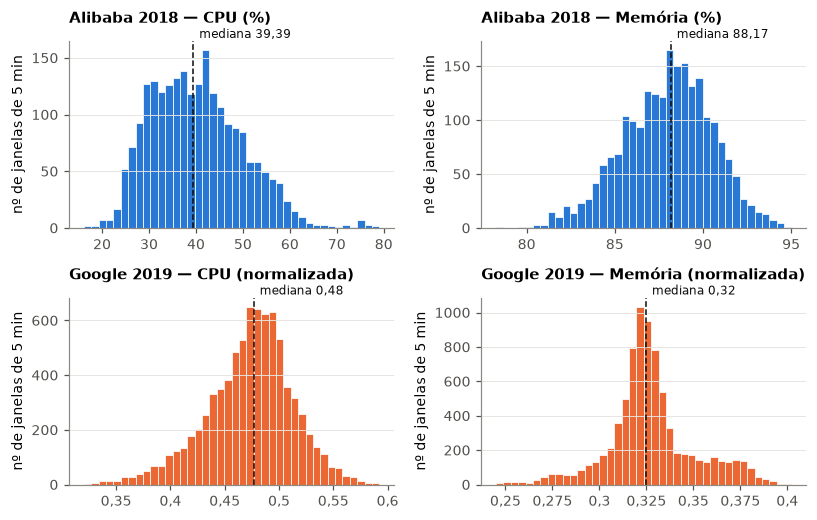

In [11]:
PARES = [
    ("Alibaba 2018", "cpu_util_percent", "CPU (%)"),
    ("Alibaba 2018", "mem_util_percent", "Memória (%)"),
    ("Google 2019", "avg_cpu", "CPU (normalizada)"),
    ("Google 2019", "avg_mem", "Memória (normalizada)"),
]

fig, axes = plt.subplots(2, 2, figsize=(7.5, 4.8))
for ax, (nome, col, rotulo) in zip(axes.flat, PARES):
    s = DATASETS[nome][col]
    ax.hist(s, bins=40, color=COR[nome], edgecolor="white", linewidth=0.5)
    ax.axvline(s.median(), color="#0b0b0b", linewidth=1, linestyle="--")
    ax.annotate(f"mediana {br(s.median(), 2)}", xy=(s.median(), 1), xycoords=("data", "axes fraction"),
                xytext=(4, 2), textcoords="offset points", fontsize=8, color="#0b0b0b")
    ax.set_title(f"{nome} — {rotulo}", pad=12)
    ax.set_ylabel("nº de janelas de 5 min")
    ax.grid(axis="x", visible=False)
eixos_br(fig)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_eda_distribuicao_cpu_memoria.png")
plt.show()

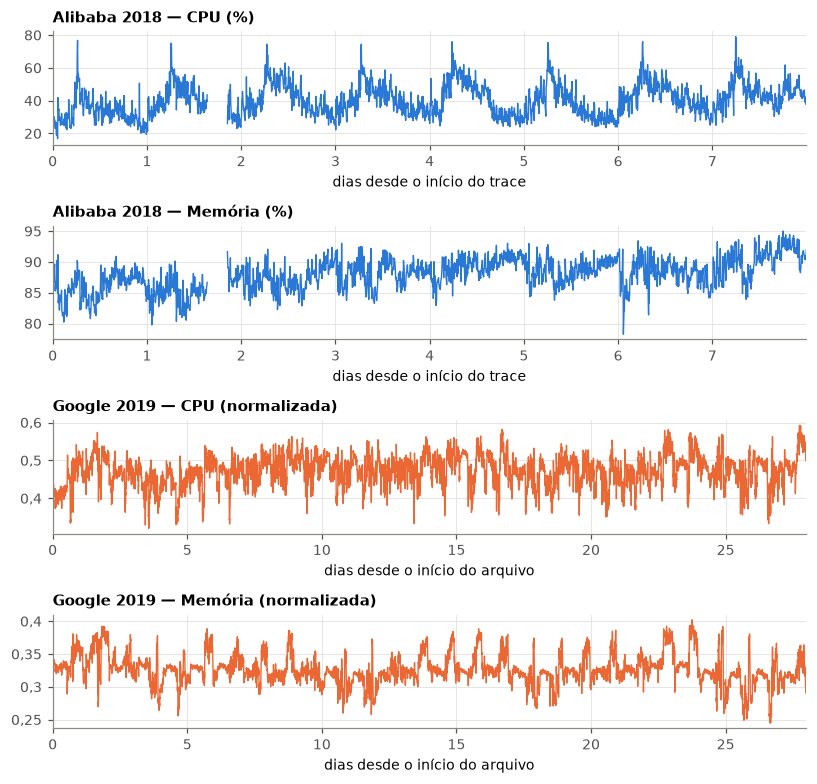

In [12]:
def com_lacunas(s):
    # Reindexa na grade regular para que a linha seja interrompida onde não há dados.
    grade = pd.timedelta_range(s.index[0], s.index[-1], freq=f"{STEP_SECONDS}s")
    return s.reindex(grade)


fig, axes = plt.subplots(4, 1, figsize=(7.5, 7.2))
for ax, (nome, col, rotulo) in zip(axes, PARES):
    s = com_lacunas(DATASETS[nome][col])
    ax.plot(em_dias(s.index), s.values, color=COR[nome])
    ax.set_title(f"{nome} — {rotulo}")
    ax.set_xlim(0, em_dias(s.index[-1]))
    ax.set_xlabel("dias desde o início do trace" if nome == "Alibaba 2018" else "dias desde o início do arquivo")
fig.tight_layout()
eixos_br(fig)
fig.savefig(FIG_DIR / "fig_eda_series_cpu_memoria.png")
plt.show()

### Sazonalidade diária

A autocorrelação no atraso de 288 janelas (24 h) mede o quanto a série se repete de um dia para o outro.
Como o Alibaba tem uma lacuna, o atraso é calculado sobre a grade regular (com a lacuna como ausente).

In [13]:
acf = pd.DataFrame(
    [{"dataset": nome, "coluna": c,
      "acf_5min": com_lacunas(df[c]).autocorr(1),
      "acf_1h": com_lacunas(df[c]).autocorr(12),
      "acf_24h": com_lacunas(df[c]).autocorr(JANELAS_POR_DIA)}
     for nome, df in DATASETS.items() for c in df.columns]
)
acf.to_csv(TAB_DIR / "tab_eda_autocorrelacao.csv", index=False)
acf

,dataset,coluna,acf_5min,acf_1h,acf_24h
0,Alibaba 2018,cpu_util_percent,0.8072,0.6306,0.6269
1,Alibaba 2018,mem_util_percent,0.7831,0.5811,0.3621
2,Alibaba 2018,net_in,0.9995,0.9992,0.9968
3,Alibaba 2018,net_out,0.9991,0.9988,0.9957
4,Alibaba 2018,disk_io_percent,0.6941,0.4838,0.4133
5,Google 2019,avg_cpu,0.9169,0.4979,0.3146
6,Google 2019,avg_mem,0.9568,0.6303,0.4310
7,Google 2019,avg_assigned_mem,0.9695,0.7167,0.4740
8,Google 2019,avg_cycles_per_instruction,0.9700,0.7229,0.3780


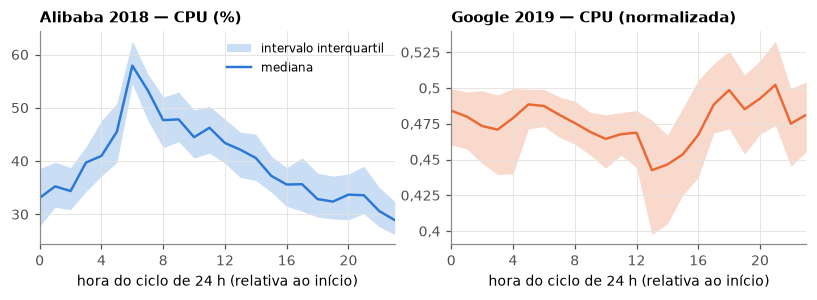

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8))
for ax, (nome, col, rotulo) in zip(axes, [PARES[0], PARES[2]]):
    s = DATASETS[nome][col]
    hora = np.floor((s.index / pd.Timedelta(hours=1)) % 24)
    perfil = s.groupby(hora).quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(perfil.index, perfil[0.25], perfil[0.75], color=COR[nome], alpha=0.25, linewidth=0,
                    label="intervalo interquartil")
    ax.plot(perfil.index, perfil[0.5], color=COR[nome], linewidth=1.6, label="mediana")
    ax.set_title(f"{nome} — {rotulo}")
    ax.set_xlabel("hora do ciclo de 24 h (relativa ao início)")
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlim(0, 23)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
eixos_br(fig)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_eda_perfil_diario_cpu.png")
plt.show()

In [15]:
pico = ali["cpu_util_percent"].groupby(np.floor(em_dias(ali.index))).idxmax()
print("Hora do pico diário de CPU no Alibaba (h desde o início do dia do trace):")
print(((pico / pd.Timedelta(hours=1)) % 24).round(2).to_dict())

Hora do pico diário de CPU no Alibaba (h desde o início do dia do trace):
{0.0: 6.33, 1.0: 6.08, 2.0: 6.5, 3.0: 6.58, 4.0: 5.75, 5.0: 6.08, 6.0: 6.25, 7.0: 5.92}


In [16]:
for nome, df in DATASETS.items():
    print(nome)
    print(df.corr().round(2).to_string(), end="\n\n")

Alibaba 2018
                  cpu_util_percent  mem_util_percent  net_in  net_out  disk_io_percent
cpu_util_percent              1.00              0.26    0.20     0.20             0.64
mem_util_percent              0.26              1.00    0.54     0.54             0.15
net_in                        0.20              0.54    1.00     1.00             0.09
net_out                       0.20              0.54    1.00     1.00             0.09
disk_io_percent               0.64              0.15    0.09     0.09             1.00

Google 2019
                            avg_cpu  avg_mem  avg_assigned_mem  avg_cycles_per_instruction
avg_cpu                        1.00     0.53              0.07                       -0.12
avg_mem                        0.53     1.00              0.44                       -0.23
avg_assigned_mem               0.07     0.44              1.00                        0.01
avg_cycles_per_instruction    -0.12    -0.23              0.01                        1.

**Leitura:**

- **Alibaba:** ciclo diário forte na CPU, com um pico agudo e recorrente por volta de 6 h depois do início de cada
  dia do trace (todos os 8 dias, entre 5,7 h e 6,5 h). É comportamento normal do cluster (carga programada), mas
  um detector pontual que olhe só o valor vai tender a marcar esse pico todo dia como anomalia. `net_in` e
  `net_out` são quase uma rampa crescente ao longo dos 8 dias (autocorrelação ≈ 1): como features, vão funcionar
  mais como "relógio" do que como sinal de carga.
- **Google:** ciclo diário mais fraco, distribuições mais concentradas. A memória tem patamares elevados que se
  repetem em alguns dias.

## 6. Existe rótulo ou proxy de falha?

O artigo promete usar "períodos dos datasets em que falhas operacionais foram documentadas pelos próprios
mantenedores". A verificação foi feita em três níveis: os CSVs do Zenodo, as tabelas do trace original da Alibaba
e a documentação oficial do Google 2019.

### 6.1 CSVs do Zenodo

Como visto na seção 1, as colunas são apenas métricas de uso. Não há rótulo, status, evento nem identificador.

### 6.2 Alibaba — status das máquinas (`machine_meta`)

O `machine_meta` é descrito como "meta info and event info of machines" e tem uma coluna `status`. As colunas
`failure_domain_1/2` **não** indicam falhas: são domínios de falha (agrupamento físico usado para espalhar réplicas).

In [17]:
st = meta["status"].value_counts().rename_axis("status").to_frame("registros")
st["máquinas"] = meta.groupby("status")["machine_id"].nunique()
st

,registros,máquinas
status,,
USING,17587,4033
IMPORT_INSTALLING,5,1


Só existem dois estados: `USING` e `IMPORT_INSTALLING` (este em uma única máquina). **Nenhum estado de falha,
manutenção ou remoção.**

### 6.3 Alibaba — status das tarefas em lote (`batch_task`)

O `batch_task` registra cada tarefa de lote com o status final. É o único lugar do trace da Alibaba com algo
parecido com "falha".

In [18]:
bt = pd.read_csv(ALI_ORIG / "batch_task.csv", header=None,
                 names=["task_name", "instance_num", "job_name", "task_type", "status",
                        "start_time", "end_time", "plan_cpu", "plan_mem"],
                 usecols=["job_name", "task_type", "status", "end_time"])
st_bt = bt["status"].value_counts().rename_axis("status").to_frame("tarefas")
st_bt["%"] = (100 * st_bt["tarefas"] / len(bt)).round(2)
st_bt

,tarefas,%
status,,
Terminated,14059143,98.35
Running,129354,0.90
Failed,83276,0.58
Waiting,23958,0.17


In [19]:
falhas = bt[bt["status"] == "Failed"]
grade = pd.RangeIndex(0, 8 * JANELAS_POR_DIA, name="janela")
por_janela = pd.DataFrame({
    "falhas": (falhas["end_time"] // STEP_SECONDS).value_counts().reindex(grade, fill_value=0),
    "encerradas": (bt["end_time"] // STEP_SECONDS).value_counts().reindex(grade, fill_value=0),
})
por_janela["taxa"] = por_janela["falhas"] / por_janela["encerradas"].replace(0, np.nan)
por_janela["dia"] = por_janela.index / JANELAS_POR_DIA

print(f"Janelas com pelo menos uma tarefa Failed: {(por_janela['falhas'] > 0).mean():.1%}")
print(f"Tarefas Failed por janela: mediana {por_janela['falhas'].median():.0f}, "
      f"p99 {por_janela['falhas'].quantile(0.99):.0f}, máximo {por_janela['falhas'].max():.0f}")
print(f"Taxa de falha (Failed / encerradas): mediana {por_janela['taxa'].median():.2%}")

Janelas com pelo menos uma tarefa Failed: 85.2%
Tarefas Failed por janela: mediana 8, p99 459, máximo 784
Taxa de falha (Failed / encerradas): mediana 0.14%


Falha de tarefa é **ruído de fundo**: aparece na maioria das janelas, porque tarefas de lote falham por motivos
da própria aplicação. Isso sozinho não serve de rótulo. O que poderia servir é um **período anormal** de falhas.
A célula abaixo procura trechos em que a média móvel de 1 h de tarefas Failed passa de 20 vezes a mediana.

In [20]:
media_1h = por_janela["falhas"].rolling(12, center=True, min_periods=1).mean()
acima = media_1h > 20 * por_janela["falhas"].median()
trechos = (acima != acima.shift()).cumsum()[acima]
RAJADAS = list(trechos.groupby(trechos).apply(lambda g: (g.index.min(), g.index.max())))

lacuna = (orig["janela"].iloc[ALIBABA_GAP_AFTER_ROW] + 1, orig["janela"].iloc[ALIBABA_GAP_AFTER_ROW + 1] - 1)
tab_rajadas = pd.DataFrame([{
    "janelas": f"{ini}–{fim}",
    "dias": f"{br(ini / JANELAS_POR_DIA, 2)}–{br((fim + 1) / JANELAS_POR_DIA, 2)}",
    "duração (h)": (fim - ini + 1) * STEP_SECONDS / 3600,
    "tarefas Failed": int(por_janela.loc[ini:fim, "falhas"].sum()),
    "jobs distintos": falhas.loc[(falhas["end_time"] // STEP_SECONDS).between(ini, fim), "job_name"].nunique(),
    "taxa média": por_janela.loc[ini:fim, "taxa"].mean(),
    "dentro da lacuna de telemetria": ini >= lacuna[0] and fim <= lacuna[1],
} for ini, fim in RAJADAS])
print(f"Taxa de falha mediana (todas as janelas): {por_janela['taxa'].median():.2%}")
tab_rajadas.to_csv(TAB_DIR / "tab_eda_alibaba_rajadas_falhas.csv", index=False)
tab_rajadas.round(3)

Taxa de falha mediana (todas as janelas): 0.14%


,janelas,dias,duração (h),tarefas Failed,jobs distintos,taxa média,dentro da lacuna de telemetria
0,506–523,"1,76–1,82",1.500,3125,3123,0.021,True
1,783–842,"2,72–2,93",5.000,17058,17057,0.040,False
2,1108–1108,"3,85–3,85",0.083,193,193,0.028,False
3,1110–1127,"3,85–3,92",1.500,3605,3603,0.029,False
4,1927–1945,"6,69–6,76",1.583,4468,4468,0.032,False
5,1954–1988,"6,78–6,91",2.917,16566,16561,0.067,False


Há seis trechos em que a taxa de falha sobe de 0,14 % para 2 % a 7 %. Em todos, o número de jobs distintos é
praticamente igual ao de tarefas: são milhares de jobs diferentes falhando ao mesmo tempo, o que sugere uma causa
comum no cluster, e não um job com defeito. Um dos trechos cai **dentro da lacuna de telemetria** do dia 1,64:
falhas em massa enquanto nenhuma máquina reportava métricas. É o indício mais forte de um incidente real no trace,
mas, justamente por estar na lacuna, não há métrica nenhuma para avaliar um detector ali.

Observação: o `batch_task` só tem tarefas encerradas a partir do dia 1; o dia 0 aparece sem falhas por ausência
de registros, não por ausência de falhas.

### 6.4 As rajadas de falha aparecem nas métricas?

Se um proxy de falha é usado como rótulo, o mínimo esperado é que o evento deixe alguma marca nas features que o
modelo enxerga. O teste precisa descontar duas coisas que não têm relação com as falhas: a tendência ao longo do
trace (a memória sobe de ~85 % para ~92 % em 8 dias) e o ciclo diário. Por isso, para cada métrica:

1. calcula-se o resíduo = valor − mediana móvel de 24 h − perfil horário típico do resíduo;
2. define-se a faixa normal como p5–p95 do resíduo nas janelas **fora** das rajadas e com cobertura completa
   (mais de 3900 máquinas);
3. mede-se a fração das janelas de cada rajada que cai fora dessa faixa. Sem efeito das falhas, a fração fica
   perto de 10 %, que é o esperado ao acaso.

`net_in`/`net_out` ficam de fora porque são uma rampa quase monotônica (seção 5).

In [21]:
METRICAS = ["cpu_util_percent", "mem_util_percent", "disk_io_percent"]

regular = ali[METRICAS].copy()
regular.index = (regular.index / pd.Timedelta(seconds=STEP_SECONDS)).astype(int)
regular = regular.reindex(grade)
hora = (grade % JANELAS_POR_DIA) // 12
tendencia = regular.rolling(JANELAS_POR_DIA, center=True, min_periods=JANELAS_POR_DIA // 2).median()
residuo = regular - tendencia
residuo = residuo - residuo.groupby(hora).transform("median")

cobertura_ok = orig.set_index("janela")["n_maquinas"].reindex(grade) > 3900
em_rajada = pd.Series(False, index=grade)
for ini, fim in RAJADAS:
    em_rajada.loc[ini:fim] = True

ref = residuo[~em_rajada & cobertura_ok]
lo, hi = ref.quantile(0.05), ref.quantile(0.95)


def fracao_fora(r):
    r = r.dropna(how="all")
    return {"janelas com métricas": len(r), **(((r < lo) | (r > hi)).mean() if len(r) else {})}


linhas = {f"{ini}–{fim}": fracao_fora(residuo.loc[ini:fim][cobertura_ok.loc[ini:fim]]) for ini, fim in RAJADAS}
linhas["todas as rajadas"] = fracao_fora(residuo[em_rajada & cobertura_ok])
linhas["fora das rajadas (referência)"] = fracao_fora(ref)
comp = pd.DataFrame(linhas).T.astype({"janelas com métricas": int})
comp.round(3).to_csv(TAB_DIR / "tab_eda_rajadas_vs_metricas.csv")
comp.round(2)

,janelas com métricas,cpu_util_percent,mem_util_percent,disk_io_percent
506–523,0,NaN,NaN,NaN
783–842,60,0.00,0.07,0.02
1108–1108,1,0.00,0.00,0.00
1110–1127,18,0.00,0.00,0.00
1927–1945,19,0.05,0.21,0.00
1954–1988,35,0.03,0.14,0.00
todas as rajadas,133,0.02,0.10,0.01
fora das rajadas (referência),1636,0.10,0.10,0.10


In [22]:
mediana_res = pd.DataFrame({f"{ini}–{fim}": residuo.loc[ini:fim].median() for ini, fim in RAJADAS}).T
print("Resíduo mediano dentro de cada rajada (unidade da métrica, em pontos percentuais):")
mediana_res.round(2)

Resíduo mediano dentro de cada rajada (unidade da métrica, em pontos percentuais):


,cpu_util_percent,mem_util_percent,disk_io_percent
506–523,NaN,NaN,NaN
783–842,-0.40,0.44,-0.36
1108–1108,-1.76,-0.76,-1.05
1110–1127,0.29,-0.65,-0.50
1927–1945,5.20,-0.64,0.99
1954–1988,0.15,-0.99,0.19


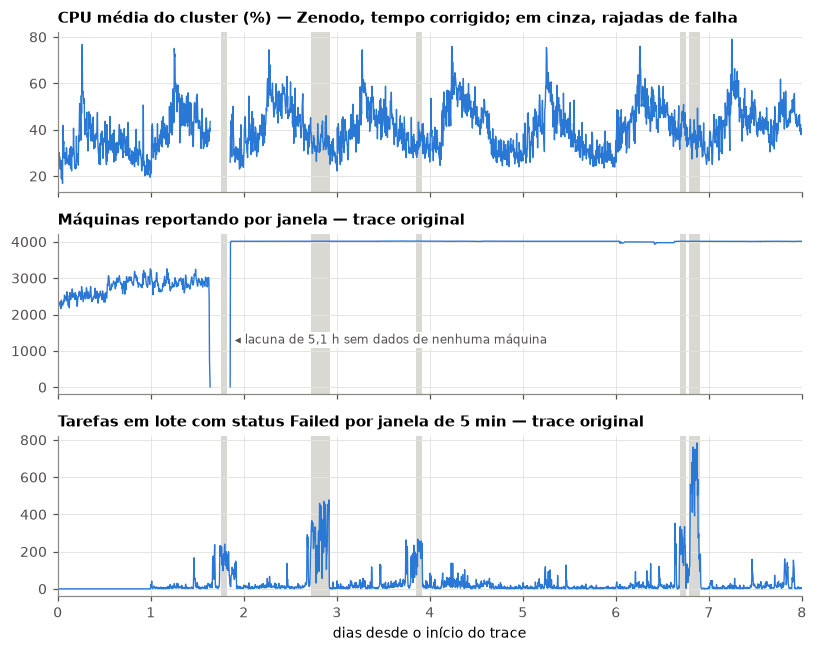

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(7.5, 6), sharex=True)
cor = COR["Alibaba 2018"]

s = com_lacunas(ali["cpu_util_percent"])
axes[0].plot(em_dias(s.index), s.values, color=cor)

n = orig.set_index("janela")["n_maquinas"].reindex(grade)
axes[1].plot(grade / JANELAS_POR_DIA, n.values, color=cor)
axes[1].set_title("Máquinas reportando por janela — trace original")
lacuna_ini = orig["janela"].iloc[ALIBABA_GAP_AFTER_ROW] + 1
axes[1].text((lacuna_ini + ALIBABA_GAP_WINDOWS) / JANELAS_POR_DIA + 0.05, 1200,
             f"◂ lacuna de {br(ALIBABA_GAP_WINDOWS * STEP_SECONDS / 3600, 1)} h sem dados de nenhuma máquina",
             fontsize=8, color=CINZA, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

axes[2].plot(por_janela["dia"], por_janela["falhas"], color=cor)
axes[2].set_title("Tarefas em lote com status Failed por janela de 5 min — trace original")
axes[2].set_xlabel("dias desde o início do trace")

for ax in axes:
    for ini, fim in RAJADAS:
        ax.axvspan(ini / JANELAS_POR_DIA, (fim + 1) / JANELAS_POR_DIA, color=DESTAQUE, linewidth=0, zorder=0)
axes[0].set_title("CPU média do cluster (%) — Zenodo, tempo corrigido; em cinza, rajadas de falha")
axes[2].set_xlim(0, 8)
eixos_br(fig)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_eda_alibaba_cobertura_e_falhas.png")
plt.show()

**Resultado:** depois de descontar tendência e ciclo diário, as rajadas ficam praticamente indistinguíveis do
resto do trace. CPU e disco saem da faixa normal **menos** do que o acaso. A memória mostra um desvio fraco
para baixo (cerca de 1 ponto percentual) só nas duas rajadas do dia 6,7–6,9. Ou seja: o proxy existe, mas **quase
não deixa marca nas métricas agregadas**. Usá-lo como rótulo de Precision/Recall/F1/FPR puniria os modelos por não
detectarem algo que as features praticamente não contêm.

Cuidado metodológico que vale registrar no TCC: numa primeira versão deste teste, sem remover a tendência, a
memória parecia anômala em ~25 % das janelas de rajada. Era efeito da rampa de memória ao longo dos 8 dias,
não das falhas.

### 6.5 Google 2019 — o que a documentação oficial permite

Segundo a documentação do *Google cluster-usage traces v3* (Wilkes, 2020):

- **`machine_events`** tem os tipos ADD, REMOVE e UPDATE. A documentação diz que uma remoção pode ocorrer por
  falha **ou** manutenção, e que um ADD posterior da mesma máquina *geralmente* indica manutenção. Ou seja, falha
  de máquina só pode ser **inferida** por heurística (REMOVE sem retorno), nunca confirmada.
- **`instance_events`** tem FAIL, mas a documentação o define como falha do **programa do usuário** (por exemplo,
  segfault ou uso de memória acima do solicitado), não da infraestrutura. EVICT mistura preempção por prioridade,
  excesso de alocação e máquina indisponível para reparo.
- Não existe tabela de incidentes, interrupções ou manutenções programadas.

Além disso, o uso prático esbarra em dois obstáculos: o trace só está disponível pelo BigQuery, e **o Zenodo não
informa qual das oito células nem quais 28 dias foram usados**, então não há como alinhar eventos do Google com o
CSV. A lição do Alibaba (seção 6.4) sugere também que eventos de máquina isolada se diluem na média de milhares
de máquinas.

### 6.6 Conclusão sobre os rótulos de falha

**Não existe, nesses dados nem nos traces originais, nenhum período de falha documentado pelos mantenedores.**
Alibaba e Google publicam eventos do escalonador, não registros de incidentes. Os proxies que existem
(REMOVE sem retorno e FAIL no Google; rajadas de tarefas Failed no Alibaba) não são "falhas documentadas";
no Google não podem ser alinhados ao CSV do Zenodo; e no Alibaba, o único que pode ser alinhado quase não aparece
nas métricas agregadas.

A frase do artigo sobre "períodos com falhas documentadas pelos mantenedores" **não é sustentada pelos dados e
precisa sair do texto do TCC.**

**Alternativa proposta:**

1. **Avaliação quantitativa principal só com injeção sintética** (já prevista no artigo), com tipos e magnitudes
   distintos entre treino e teste.
2. **Estudo de caso com dados reais, qualitativo:** verificar se os escores dos modelos sobem nas cinco rajadas de
   falha do Alibaba que têm métricas, apresentando-as como *proxy derivado pelo autor*, não como falha documentada.
   Um resultado negativo também é resultado: mostra o limite de detectar falhas em métricas agregadas de cluster.
3. **Terceiro dataset (adotado):** incluir o *Numenta Anomaly Benchmark* (NAB, licença MIT), que tem
   17 séries reais do AWS CloudWatch (CPU, rede e disco de EC2, RDS e ELB) com janelas de anomalia rotuladas, e
   séries com causa conhecida, como uma falha documentada de servidores de API da AWS. É a única forma encontrada
   de ter avaliação com anomalias reais rotuladas, e ainda conversa com a parte AWS do TCC. Custo: um terceiro
   dataset, univariado, não previsto no artigo.

## 7. Resumo para a fase 3

| Tema | Achado | Decisão pendente para a fase 3 |
|---|---|---|
| Granularidade | 1 série agregada por dataset, janelas de 5 min; 2243 (Alibaba) e 8064 (Google) pontos | Comparação será sobre comportamento do cluster, não de máquinas |
| Tempo | Sem coluna de tempo; Alibaba tem lacuna de ≈ 5 h no dia 1,64 (já corrigida em `src/data.py`) | Google: assumir passo regular e registrar como limitação |
| Cobertura | Alibaba: ~2,3 mil máquinas antes da lacuna, ~4 mil depois; 2 janelas com 8 e 15 máquinas | Descartar/sinalizar janelas de cobertura baixa; avaliar usar a série reconstruída do original |
| Sazonalidade | Ciclo diário forte no Alibaba (pico ~6 h após o início de cada dia) | Incluir features de contexto temporal ou trabalhar sobre resíduo dessazonalizado |
| `net_in`/`net_out` | Rampa quase monotônica ao longo do trace | Avaliar remover ou diferenciar |
| Rótulos reais | Inexistentes (seção 6) | Avaliação principal só com injeção sintética |